In [1]:
import pandas as pd

# Read Excel file
df = pd.read_excel("latest_transactions.xlsx", sheet_name=0, skiprows=8)

In [2]:
#rename column names
df = df.rename(columns={
    '거래 일시': 'Date',
    '적요': 'Remarks',
    '거래 유형': 'Transaction_Type',
    '거래 기관': 'Bank_Name',
    '계좌번호': 'Account_Number',
    '거래 금액': 'Transaction_Amount',
    '거래 후 잔액': 'Balance',
    '메모': 'Memo'
})

# drop columns
df = df.drop(columns=['Unnamed: 0', 'Memo'])

# fill na with 0 and convert to int
df["Account_Number"] = df["Account_Number"].fillna(0).astype(int)

In [3]:
#translate transaction_type column to english
df['Transaction_Type'] = df['Transaction_Type'].replace({
    '체크카드결제': 'Check Card',
    '입금': 'Deposit',
    '출금': 'Withdrawal',
    '프로모션입금': 'Cashback',
    '오픈뱅킹': 'Open Banking',
    '이자입금': 'Interest Deposit',
    'ATM출금': 'ATM Withdrawal',
    'BC카드': 'ATM Deposit'
})

In [4]:
df['Date'] = pd.to_datetime(df['Date'], format='%Y.%m.%d %H:%M:%S')

df['Time'] = df['Date'].dt.time
df['Date'] = df['Date'].dt.date

# Reorder
df = df[['Date', 'Time'] + [col for col in df.columns if col not in ['Date', 'Time']]]

# Save to csv
df.to_csv('transactions.csv', index=False, encoding="utf-8")

In [5]:
import pandas as pd

df = pd.read_csv('transactions.csv')
df.head(10)

,Date,Time,Remarks,Transaction_Type,Bank_Name,Account_Number,Transaction_Amount,Balance
0,2025-09-24,09:15:09,인하씨앤피(C P),Check Card,NaN,0,-50,2117714.0
1,2025-09-23,21:47:56,허리스 (HOLIS),Check Card,NaN,0,-14500,2117764.0
2,2025-09-23,20:11:14,KARIMBERDI,Deposit,NH농협지역조합,0,145000,2132264.0
3,2025-09-23,17:37:05,카드 캐시백,Cashback,NaN,0,100,1987264.0
4,2025-09-23,14:05:25,신수연,Deposit,카카오뱅크,0,87000,1987164.0
5,2025-09-23,12:17:32,ABDUKARIMOV HUMOYUNBEK OLIMJON UGLI,Deposit,토스뱅크,0,59636,1900164.0
6,2025-09-23,12:04:42,KURBONALIE,Deposit,하나은행,0,13000,1840528.0
7,2025-09-23,08:50:18,이마트24 인하대도서관점,Check Card,NaN,0,-2300,1827528.0
8,2025-09-22,22:22:10,허리스 (HOLIS),Check Card,NaN,0,-4800,1829828.0
9,2025-09-22,21:52:30,MUSTAFAKULOV AZIZBEK FURKAT UGLI,Deposit,토스뱅크,0,117000,1834628.0


In [72]:
import pandas as pd

df = pd.read_csv('transactions.csv')
df.to_excel("formatted_transactions.xlsx", index=False)

In [6]:
import pandas as pd

df = pd.read_csv('transactions.csv')

def total_by_unique_remarks(df, name):
    mask = df['Remarks'].str.contains(name, na=False, case=False)
    total_spent = df.loc[mask, 'Transaction_Amount'].sum()
    print(f"Total spent at {name}:", total_spent)

# total_by_unique_remarks(tr, '페이브')
# total_by_unique_remarks(tr, '카드 캐시백')
# total_by_unique_remarks(df, '통장 이자')
# total_by_unique_remarks(df, '김용채')
# total_by_unique_remarks(df, '이마트24')
# total_by_unique_remarks(df, '스마일마트')
# total_by_unique_remarks(df, '셔호나')
# total_by_unique_remarks(df, 'SENTBE')
# total_by_unique_remarks(df, '나우커피 인하대점')
# total_by_unique_remarks(df, '건강TOSHNIYO')
# total_by_unique_remarks(df, 'TOSHNIYO')
# total_by_unique_remarks(df, 'CU')

In [7]:
def column_value_counts(df, name):
    print(df[name].value_counts())
    
column_value_counts(df, 'Remarks')

Remarks
카드 캐시백                                 47
이마트24 인하대도서관점                          44
KURBONALIE                             43
허리스 (HOLIS)                            33
ABDUKARIMOV HUMOYUNBEK OLIMJON UGLI    25
                                       ..
SIDDIKOV J                              1
주재란                                     1
세븐일레븐검단중앙점                              1
인하생활용품                                  1
KOSIMOVOMA                              1
Name: count, Length: 129, dtype: int64


In [8]:
def individual_transactions(name):
    mask = df['Remarks'].str.contains(name, na=False, case=False)
    # transactions_of_individual = df[mask]   
    # Calculate totals by Remarks type
    withdrawal_mask = mask & (df['Transaction_Type'] == 'Withdrawal')
    deposit_mask = mask & (df['Transaction_Type'] == 'Deposit')

    total_withdrawal = df.loc[withdrawal_mask, 'Transaction_Amount'].sum()
    total_deposit = df.loc[deposit_mask, 'Transaction_Amount'].sum()

    print(f'\n{name} Summary:')
    # print(transactions_of_individual[['Date', 'Transaction_Type', 'Transaction_Amount', 'Bank_Name']])
    print(f'Withdrawals: {total_withdrawal} KRW ({withdrawal_mask.sum()} transactions)')
    print(f'Deposits: {total_deposit} KRW ({deposit_mask.sum()} transactions)')
    print(f'Net amount: {total_deposit - total_withdrawal} KRW')
    
individual_transactions('ABDUKARIMOV HUMOYUNBEK')
# individual_transactions('KURBONALIE')
# individual_transactions('MUNTOXIROV')
# individual_transactions('NAJIMOV OTABEK')
# individual_transactions('KIYOMOV')
# individual_transactions('ISMAILOV')


ABDUKARIMOV HUMOYUNBEK Summary:
Withdrawals: -252000 KRW (11 transactions)
Deposits: 1915334 KRW (14 transactions)
Net amount: 2167334 KRW


=== CASH FLOW CORE KPIs ===
Total Income: 17,505,241 KRW
Total Expenses: 15,456,029 KRW
Net Flow: 2,049,212 KRW
Savings Rate: 11.7%

=== MONTHLY TRENDS ===
2025-04: Income 886,348 KRW | Expenses 885,350 KRW | Net 998 KRW
2025-05: Income 1,090,799 KRW | Expenses 941,402 KRW | Net 149,397 KRW
2025-06: Income 3,230,738 KRW | Expenses 3,341,155 KRW | Net -110,417 KRW
2025-07: Income 4,370,976 KRW | Expenses 4,029,420 KRW | Net 341,556 KRW
2025-08: Income 2,154,890 KRW | Expenses 2,556,904 KRW | Net -402,014 KRW
2025-09: Income 5,771,490 KRW | Expenses 3,701,798 KRW | Net 2,069,692 KRW


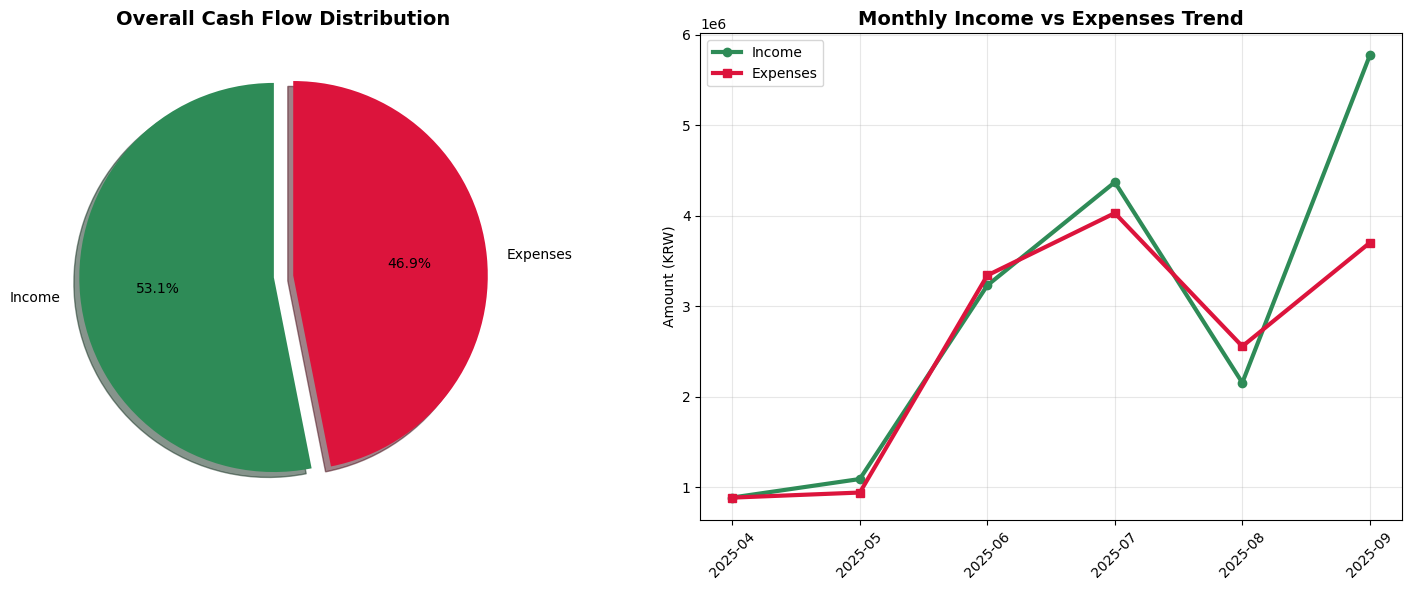


✅ Dashboard saved as 'cash_flow_kpis_dashboard.png'


In [9]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('transactions.csv')

# Parse date and create month column
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Month'] = df['DateTime'].dt.to_period('M')

# 1) Cash Flow Core KPIs
# Categorize transactions
income_types = ['Deposit', 'Cashback', 'Interest Deposit']
expense_types = ['Withdrawal', 'Check Card', 'ATM Withdrawal']

income_data = df[df['Transaction_Type'].isin(income_types)]
expense_data = df[df['Transaction_Type'].isin(expense_types)]

# Calculate totals
total_income = income_data['Transaction_Amount'].sum()
total_expenses = abs(expense_data['Transaction_Amount'].sum())  # Make positive
net_flow = total_income - total_expenses

print("=== CASH FLOW CORE KPIs ===")
print(f"Total Income: {total_income:,.0f} KRW")
print(f"Total Expenses: {total_expenses:,.0f} KRW") 
print(f"Net Flow: {net_flow:,.0f} KRW")
print(f"Savings Rate: {(net_flow/total_income)*100:.1f}%")

# 2) Monthly Trends
monthly_income = income_data.groupby('Month')['Transaction_Amount'].sum()
monthly_expenses = expense_data.groupby('Month')['Transaction_Amount'].sum().abs()
monthly_net = monthly_income - monthly_expenses

print("\n=== MONTHLY TRENDS ===")
for month in monthly_income.index:
    income = monthly_income.get(month, 0)
    expenses = monthly_expenses.get(month, 0)
    net = income - expenses
    print(f"{month}: Income {income:,.0f} KRW | Expenses {expenses:,.0f} KRW | Net {net:,.0f} KRW")

# Dashboard Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# 1) Overall Cash Flow Pie Chart
sizes = [total_income, total_expenses]
labels = ['Income', 'Expenses']
colors = ['#2E8B57', '#DC143C']
explode = (0.05, 0.05)

ax1.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', 
        startangle=90, explode=explode, shadow=True)
ax1.set_title('Overall Cash Flow Distribution', fontsize=14, fontweight='bold')

# 2) Monthly Trend Line Chart
months = [str(m) for m in monthly_income.index]
ax2.plot(months, monthly_income.values, marker='o', linewidth=3, 
         label='Income', color='#2E8B57')
ax2.plot(months, monthly_expenses.values, marker='s', linewidth=3, 
         label='Expenses', color='#DC143C')
ax2.set_title('Monthly Income vs Expenses Trend', fontsize=14, fontweight='bold')
ax2.set_ylabel('Amount (KRW)')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('visuals/cash_flow_kpis_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Dashboard saved as 'cash_flow_kpis_dashboard.png'")

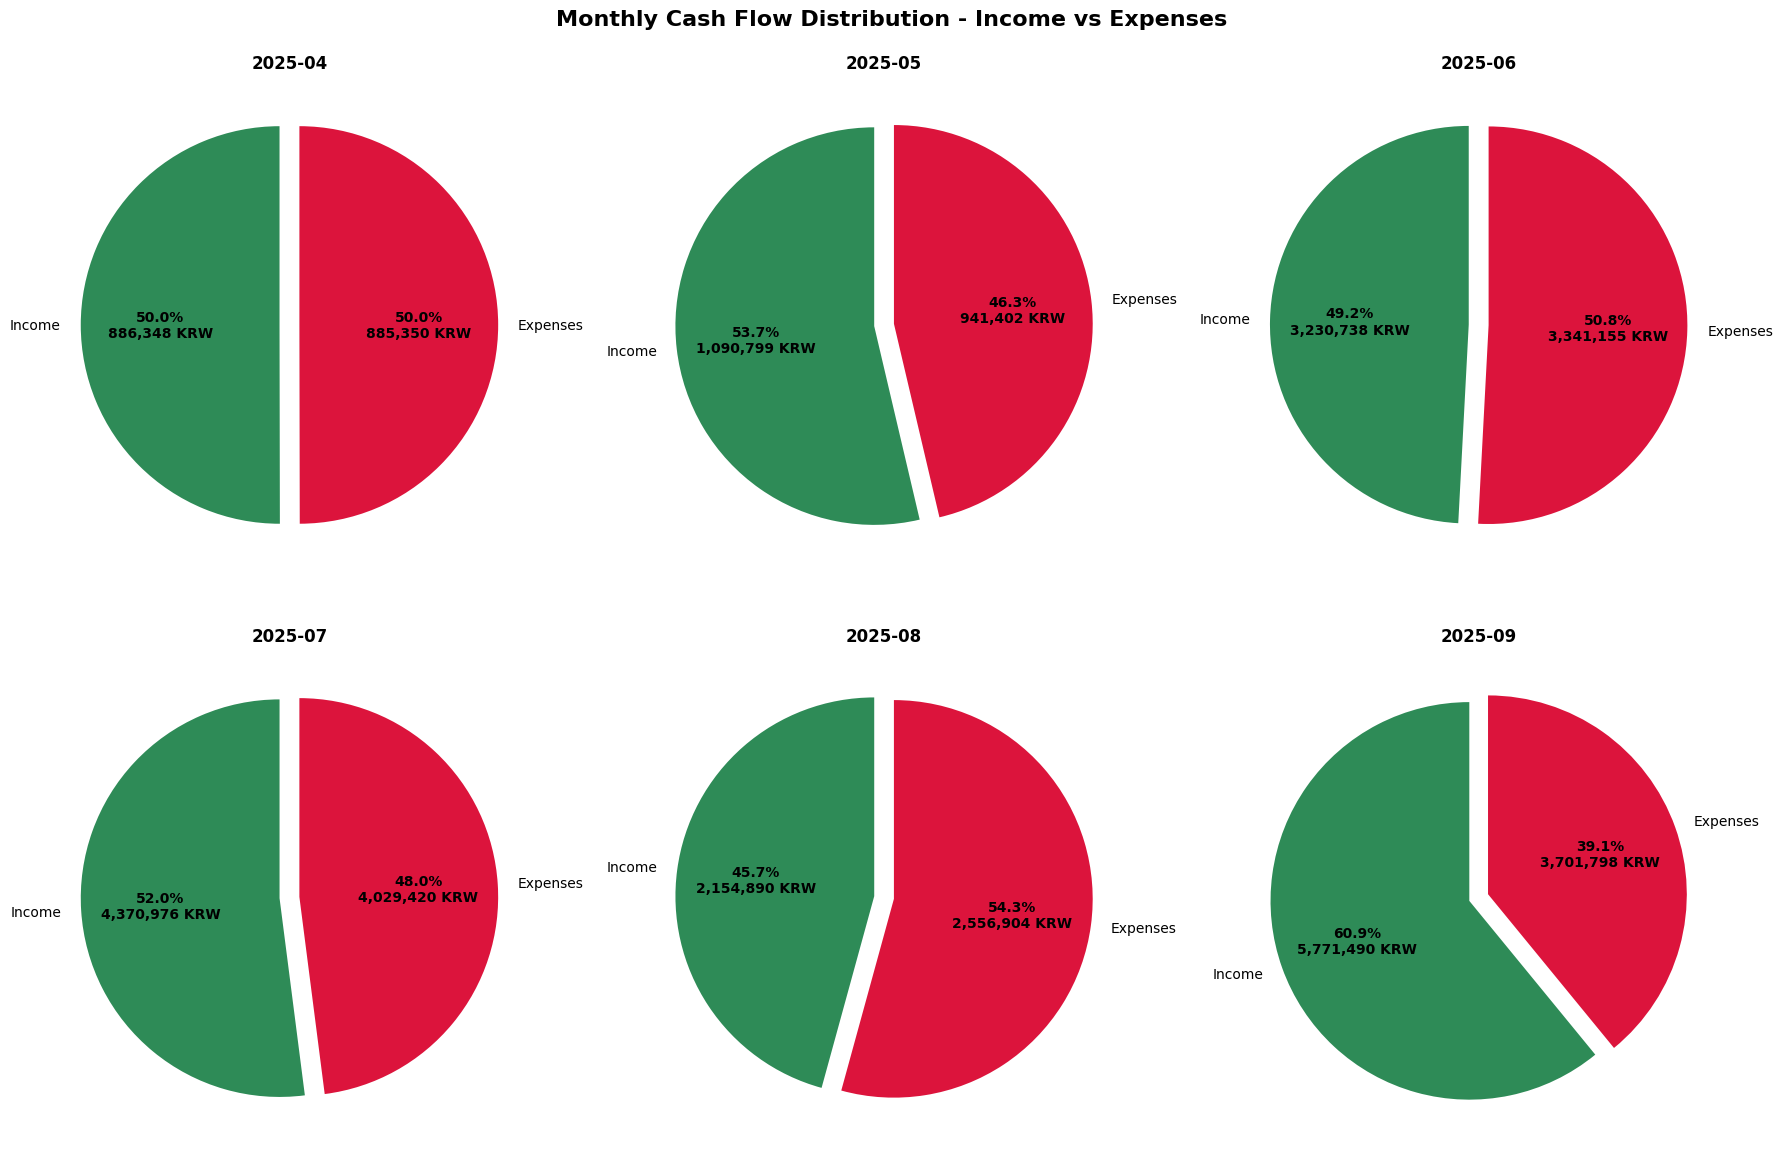

✅ Monthly Cash Flow Breakdown saved as 'monthly_cash_flow_breakdown.png'

=== MONTHLY BREAKDOWN SUMMARY ===
2025-04: Income 886,348 KRW | Expenses 885,350 KRW | Net 998 KRW
2025-05: Income 1,090,799 KRW | Expenses 941,402 KRW | Net 149,397 KRW
2025-06: Income 3,230,738 KRW | Expenses 3,341,155 KRW | Net -110,417 KRW
2025-07: Income 4,370,976 KRW | Expenses 4,029,420 KRW | Net 341,556 KRW
2025-08: Income 2,154,890 KRW | Expenses 2,556,904 KRW | Net -402,014 KRW
2025-09: Income 5,771,490 KRW | Expenses 3,701,798 KRW | Net 2,069,692 KRW


In [10]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('transactions.csv')

# Parse date and create month column
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Month'] = df['DateTime'].dt.to_period('M')

# Categorize transactions
income_types = ['Deposit', 'Cashback', 'Interest Deposit']
expense_types = ['Withdrawal', 'Check Card', 'ATM Withdrawal']

income_data = df[df['Transaction_Type'].isin(income_types)]
expense_data = df[df['Transaction_Type'].isin(expense_types)]

# Calculate monthly totals
monthly_income = income_data.groupby('Month')['Transaction_Amount'].sum()
monthly_expenses = expense_data.groupby('Month')['Transaction_Amount'].sum().abs()

# Create custom autopct function to show both percentage and amount
def autopct_format(values):
    def inner_autopct(pct):
        total = sum(values)
        val = int(round(pct * total / 100.0))
        return f"{pct:.1f}%\n{val:,.0f} KRW"
    return inner_autopct

# Create subplots for each month
months = monthly_income.index
n_months = len(months)
cols = 3
rows = (n_months + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(18, 6*rows))
fig.suptitle('Monthly Cash Flow Distribution - Income vs Expenses', fontsize=16, fontweight='bold')

if rows == 1:
    axes = [axes] if n_months == 1 else axes
else:
    axes = axes.flatten()

colors = ['#2E8B57', '#DC143C']  # Green for income, Red for expenses
labels = ['Income', 'Expenses']

for i, month in enumerate(months):
    income = monthly_income.get(month, 0)
    expenses = monthly_expenses.get(month, 0)
    
    if income > 0 or expenses > 0:
        sizes = [income, expenses]
        
        # Create pie chart with amounts
        wedges, texts, autotexts = axes[i].pie(
            sizes, 
            labels=labels, 
            colors=colors,
            autopct=autopct_format(sizes),
            startangle=90,
            explode=(0.05, 0.05)
        )
        
        # Style the text
        for autotext in autotexts:
            autotext.set_fontsize(10)
            autotext.set_fontweight('bold')
            
        axes[i].set_title(f'{month}', fontweight='bold', fontsize=12)
    else:
        axes[i].text(0.5, 0.5, 'No Data', ha='center', va='center', 
                    transform=axes[i].transAxes, fontsize=12)
        axes[i].set_title(f'{month}', fontweight='bold', fontsize=12)

# Hide unused subplots
for i in range(n_months, len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.savefig('visuals/monthly_cash_flow_breakdown.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("✅ Monthly Cash Flow Breakdown saved as 'monthly_cash_flow_breakdown.png'")

# Print summary
print("\n=== MONTHLY BREAKDOWN SUMMARY ===")
for month in months:
    income = monthly_income.get(month, 0)
    expenses = monthly_expenses.get(month, 0)
    net = income - expenses
    print(f"{month}: Income {income:,.0f} KRW | Expenses {expenses:,.0f} KRW | Net {net:,.0f} KRW")

=== TRANSACTION TYPE BREAKDOWN ===
                  Count  Total_Amount  Average_Amount  Median_Amount  \
Transaction_Type                                                       
Deposit             126      17499711        138887.0        80000.0   
Withdrawal          103     -13774937       -133737.0       -20000.0   
Check Card          305      -1601092         -5249.0        -2500.0   
ATM Deposit           1         90000         90000.0        90000.0   
ATM Withdrawal        3        -80000        -26667.0       -20000.0   
Open Banking          6        -21498         -3583.0        -4000.0   
Cashback             47          5100           109.0          100.0   
Interest Deposit      5           430            86.0           69.0   

                  Volume_Share_%  Value_Share_%  
Transaction_Type                                 
Deposit                     21.1           52.9  
Withdrawal                  17.3           41.7  
Check Card                  51.2            

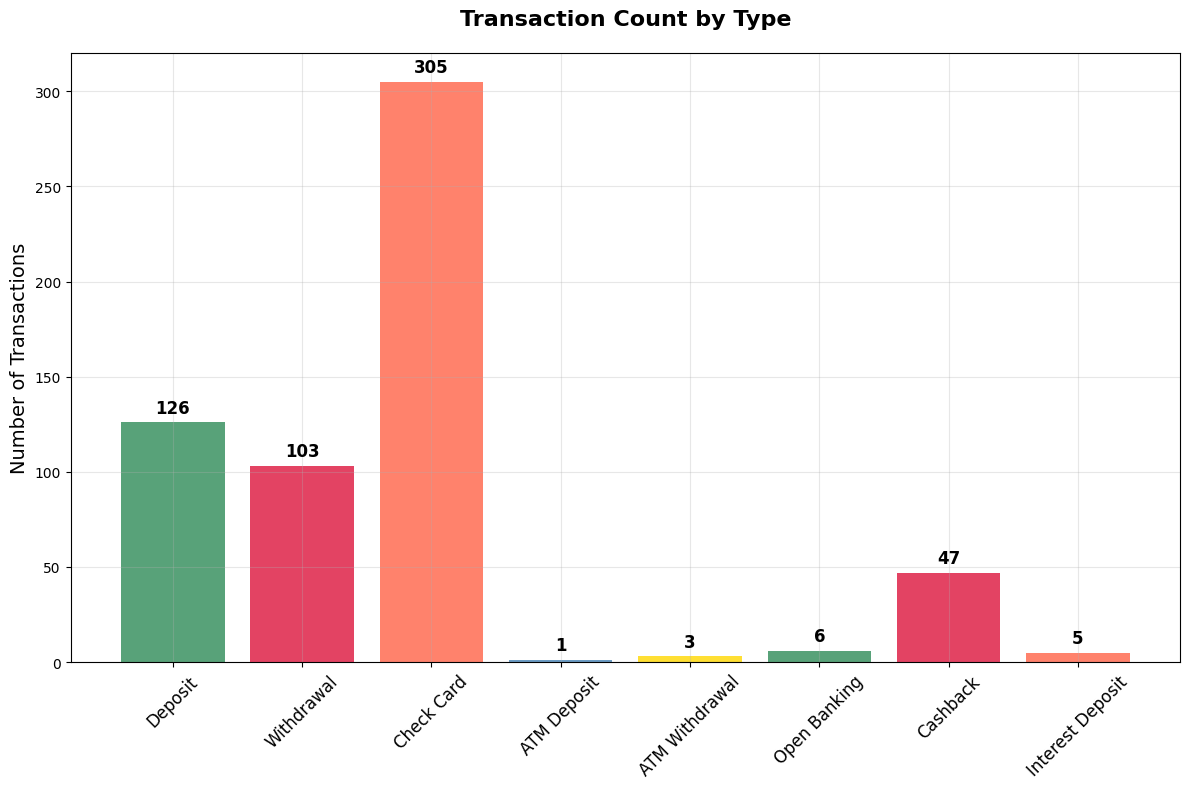

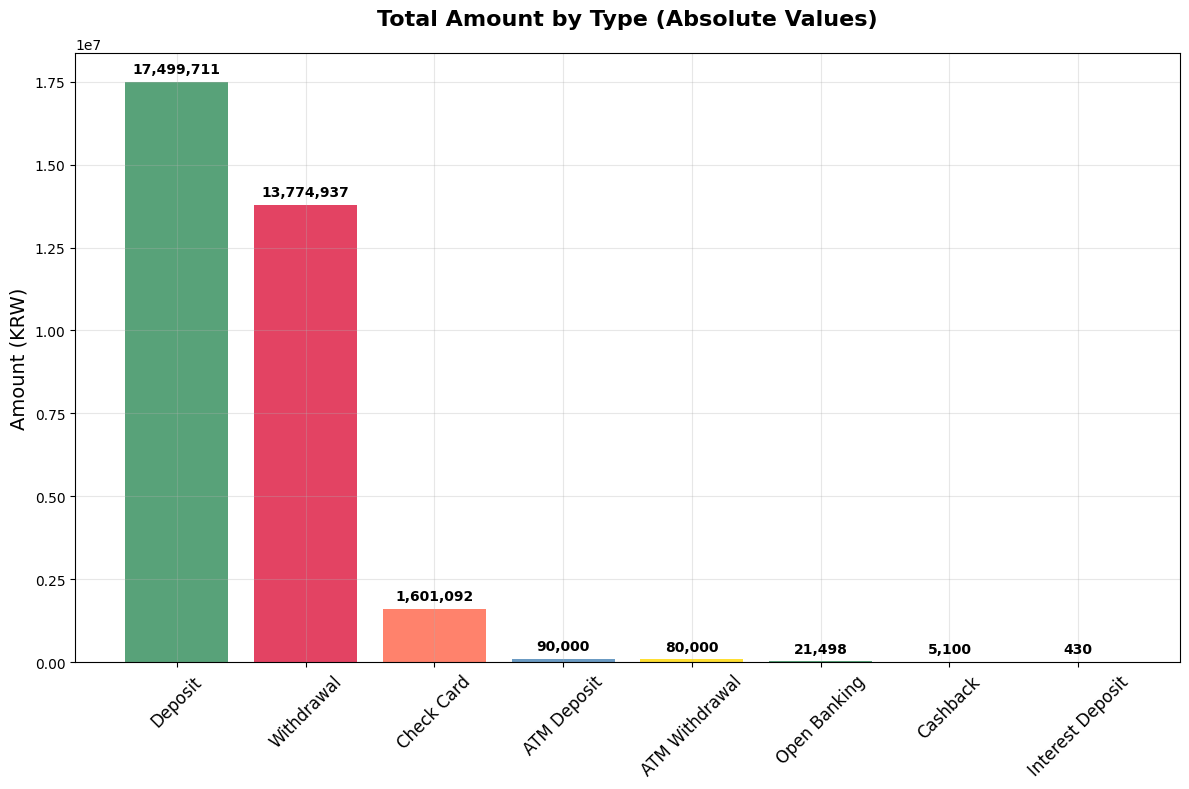

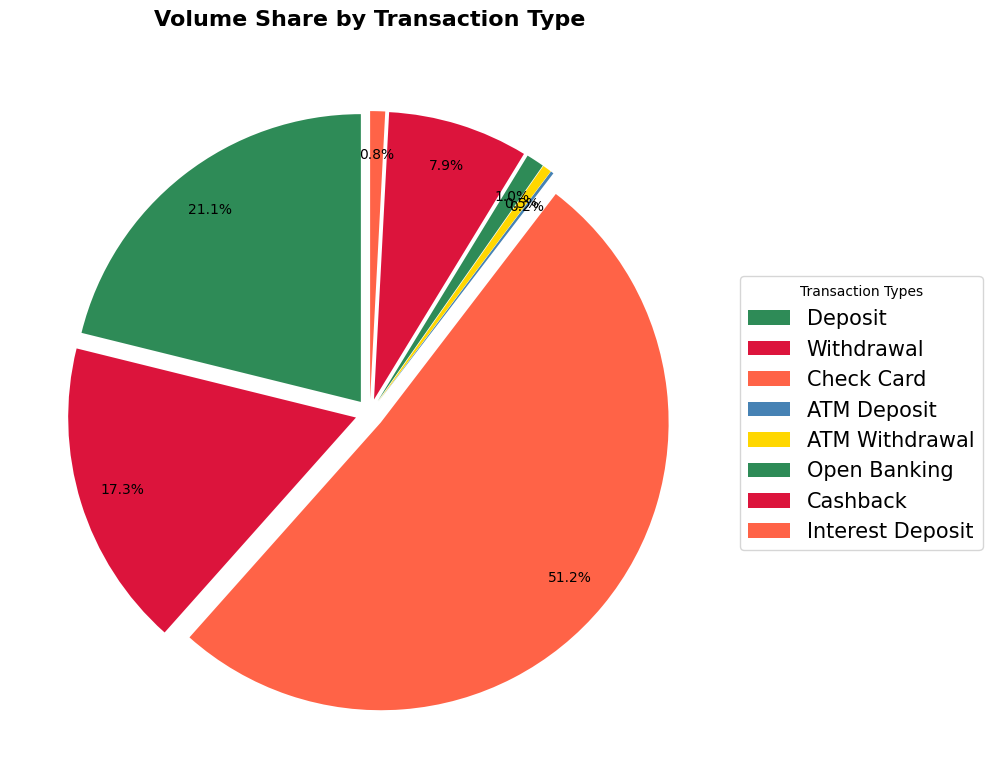


✅ Four separate charts saved:
1. transaction_count_by_type.png
2. total_amount_by_type.png
3. volume_share_pie_chart.png


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('transactions.csv')

# Parse date and create month column
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Transaction_Amount'] = pd.to_numeric(df['Transaction_Amount'])

# Transaction-Type Breakdown Analysis
transaction_stats = df.groupby('Transaction_Type').agg({
    'Transaction_Amount': ['count', 'sum', 'mean', 'median']
}).round(0)

# Flatten column names
transaction_stats.columns = ['Count', 'Total_Amount', 'Average_Amount', 'Median_Amount']

# Calculate percentages
total_transactions = df.shape[0]
total_volume = df['Transaction_Amount'].abs().sum()

transaction_stats['Volume_Share_%'] = (transaction_stats['Count'] / total_transactions * 100).round(1)
transaction_stats['Value_Share_%'] = (transaction_stats['Total_Amount'].abs() / total_volume * 100).round(1)

# Sort by total amount (absolute value)
transaction_stats = transaction_stats.reindex(
    transaction_stats['Total_Amount'].abs().sort_values(ascending=False).index
)

print("=== TRANSACTION TYPE BREAKDOWN ===")
print(transaction_stats)

colors = ['#2E8B57', '#DC143C', '#FF6347', '#4682B4', '#FFD700']

# Plot 1: Transaction Count by Type
plt.figure(figsize=(12, 8))
bars = plt.bar(transaction_stats.index, transaction_stats['Count'], color=colors, alpha=0.8)
plt.title('Transaction Count by Type', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Number of Transactions', fontsize=14)
plt.xticks(rotation=45, fontsize=12)
plt.grid(True, alpha=0.3)

# Add value labels on bars
for i, v in enumerate(transaction_stats['Count']):
    plt.text(i, v + max(transaction_stats['Count'])*0.01, str(int(v)), 
             ha='center', va='bottom', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.savefig('visuals/transaction_count_by_type.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# Plot 2: Total Amount by Type
plt.figure(figsize=(12, 8))
abs_amounts = transaction_stats['Total_Amount'].abs()
bars = plt.bar(transaction_stats.index, abs_amounts, color=colors, alpha=0.8)
plt.title('Total Amount by Type (Absolute Values)', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Amount (KRW)', fontsize=14)
plt.xticks(rotation=45, fontsize=12)
plt.grid(True, alpha=0.3)

# Add value labels
for i, v in enumerate(abs_amounts):
    plt.text(i, v + max(abs_amounts)*0.01, f'{int(v):,}', 
             ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('visuals/total_amount_by_type.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# Plot 3: Volume Share Pie Chart
plt.figure(figsize=(10, 10))
plt.pie(transaction_stats['Count'], labels=None, autopct='%1.1f%%', colors=colors, startangle=90, explode=[0.05]*len(transaction_stats), pctdistance=0.85)
plt.legend(
    transaction_stats.index, 
    title="Transaction Types", 
    loc="center left", 
    bbox_to_anchor=(1, 0, 0.5, 1),  # move legend outside
    fontsize=15
)

# Make percentage text bold and larger
for autotext in autotexts:
    autotext.set_fontweight('bold')
    autotext.set_fontsize(14)

plt.title('Volume Share by Transaction Type', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('visuals/volume_share_pie_chart.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# # Plot 4: Average Amount by Type
# plt.figure(figsize=(12, 8))
# avg_amounts = transaction_stats['Average_Amount'].abs()
# bars = plt.barh(transaction_stats.index, avg_amounts, color=colors, alpha=0.8)
# plt.title('Average Amount by Type', fontsize=16, fontweight='bold', pad=20)
# plt.xlabel('Average Amount (KRW)', fontsize=14)
# plt.yticks(fontsize=12)
# plt.grid(True, alpha=0.3)

# # Add value labels
# for i, v in enumerate(avg_amounts):
#     plt.text(v + max(avg_amounts)*0.01, i, f'{int(v):,}', 
#              va='center', fontweight='bold', fontsize=11)

# plt.tight_layout()
# plt.savefig('visuals/average_amount_by_type.png', dpi=300, bbox_inches='tight', facecolor='white')
# plt.show()

print("\n✅ Four separate charts saved:")
print("1. transaction_count_by_type.png")
print("2. total_amount_by_type.png") 
print("3. volume_share_pie_chart.png")
# print("4. average_amount_by_type.png")

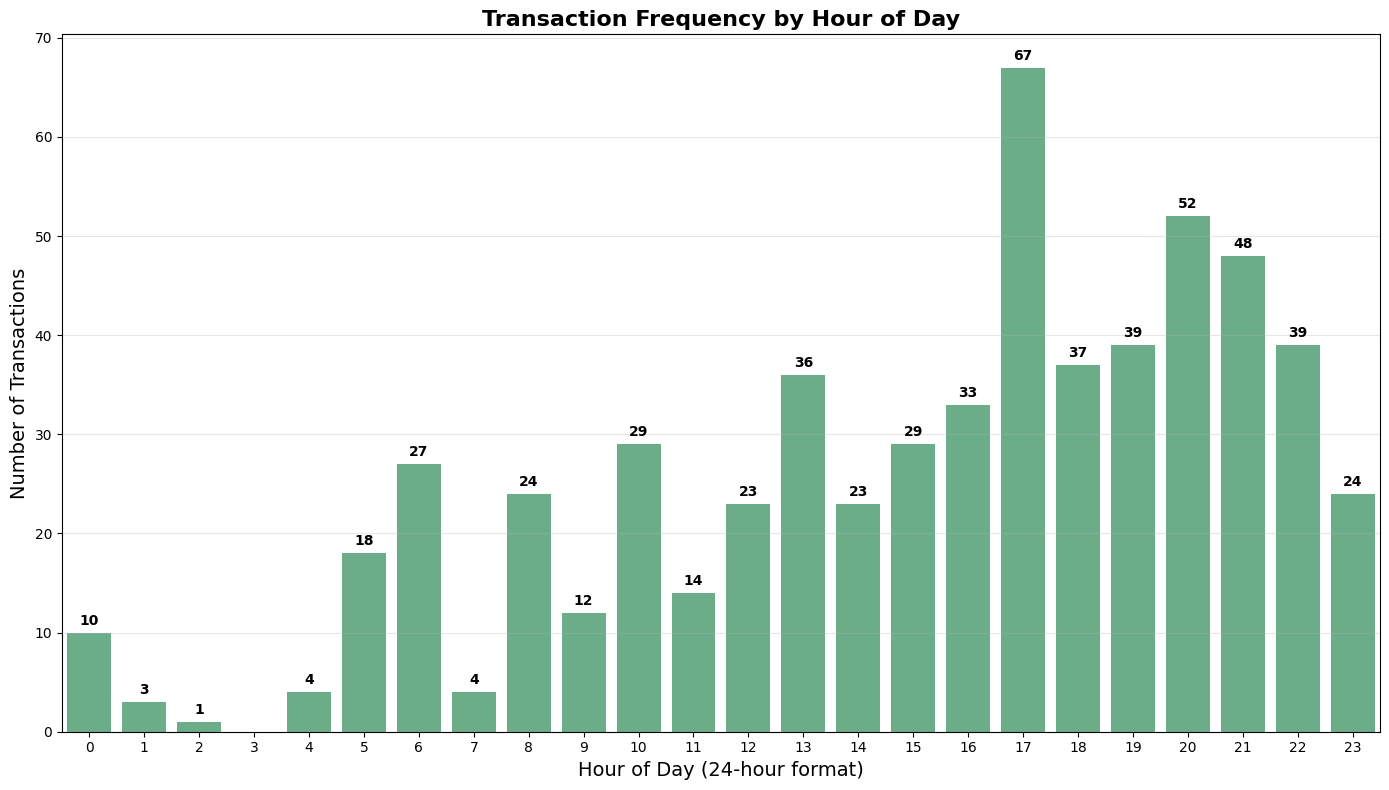

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the data
df = pd.read_csv('transactions.csv')

# Combine Date and Time columns, then parse
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Hour'] = df['DateTime'].dt.hour

# Count transactions per hour
hourly_counts = df['Hour'].value_counts().sort_index()

# Create histogram
plt.figure(figsize=(14, 8))
plt.bar(hourly_counts.index, hourly_counts.values, color='#2E8B57', alpha=0.7)

plt.title('Transaction Frequency by Hour of Day', fontsize=16, fontweight='bold')
plt.xlabel('Hour of Day (24-hour format)', fontsize=14)
plt.ylabel('Number of Transactions', fontsize=14)

# Set x-axis to show all 24 hours
plt.xticks(range(0, 24))
plt.xlim(-0.5, 23.5)
plt.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for i, v in hourly_counts.items():
    plt.text(i, v + 0.5, str(v), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('visuals/hourly_transaction_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

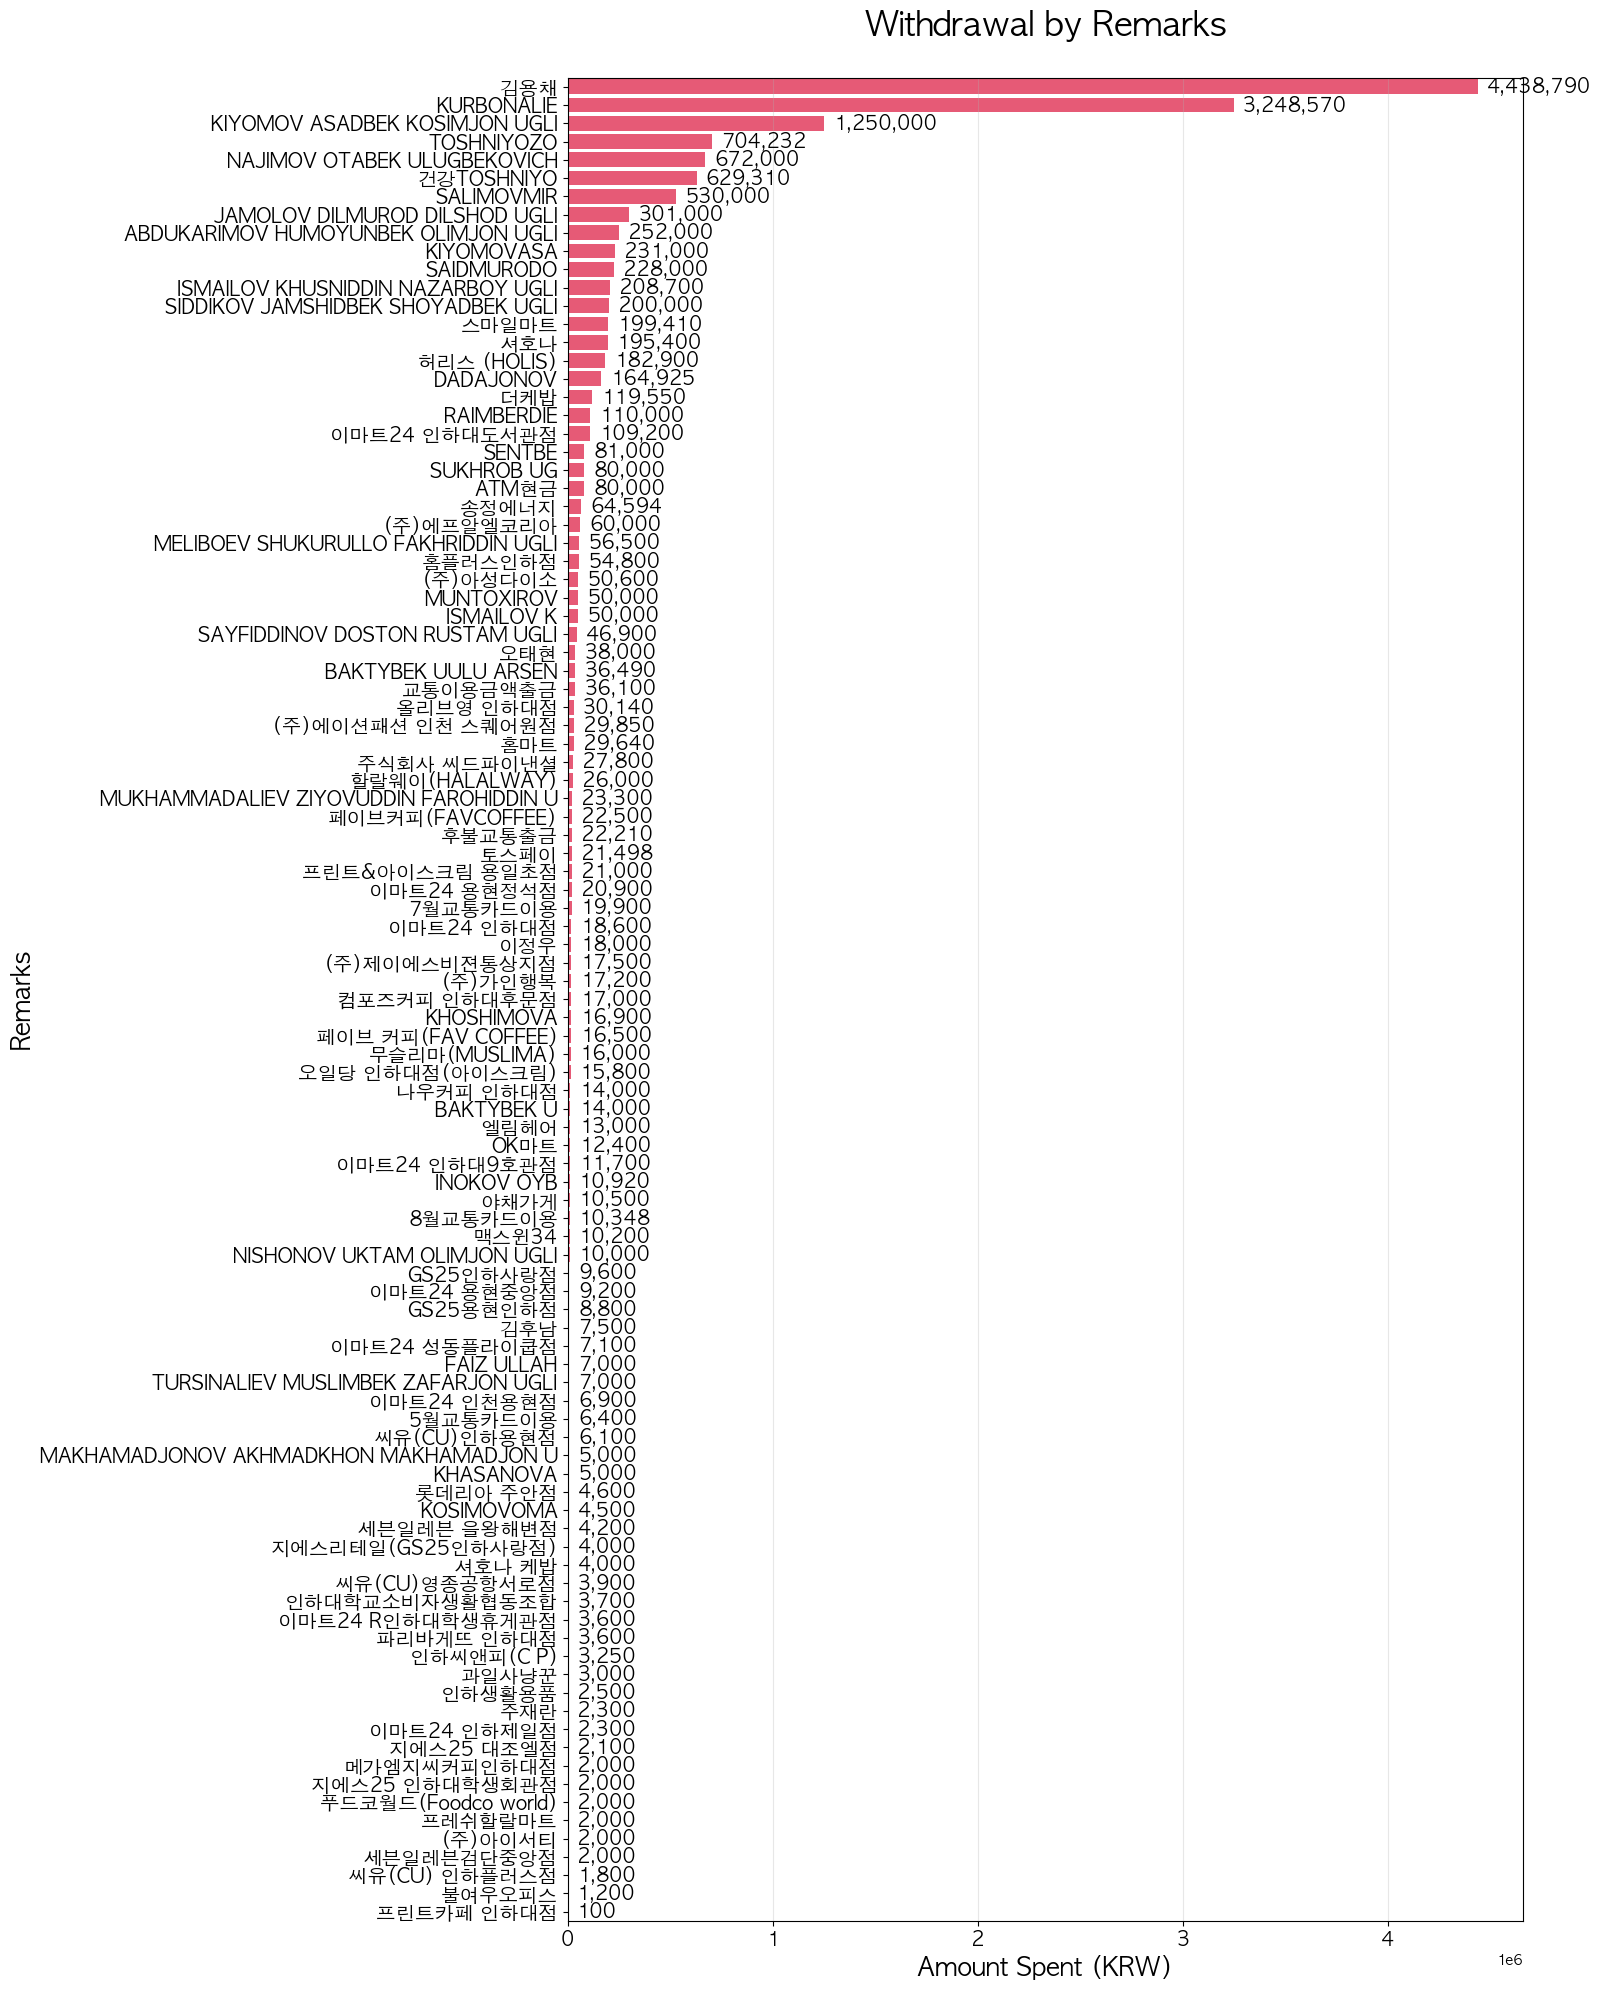

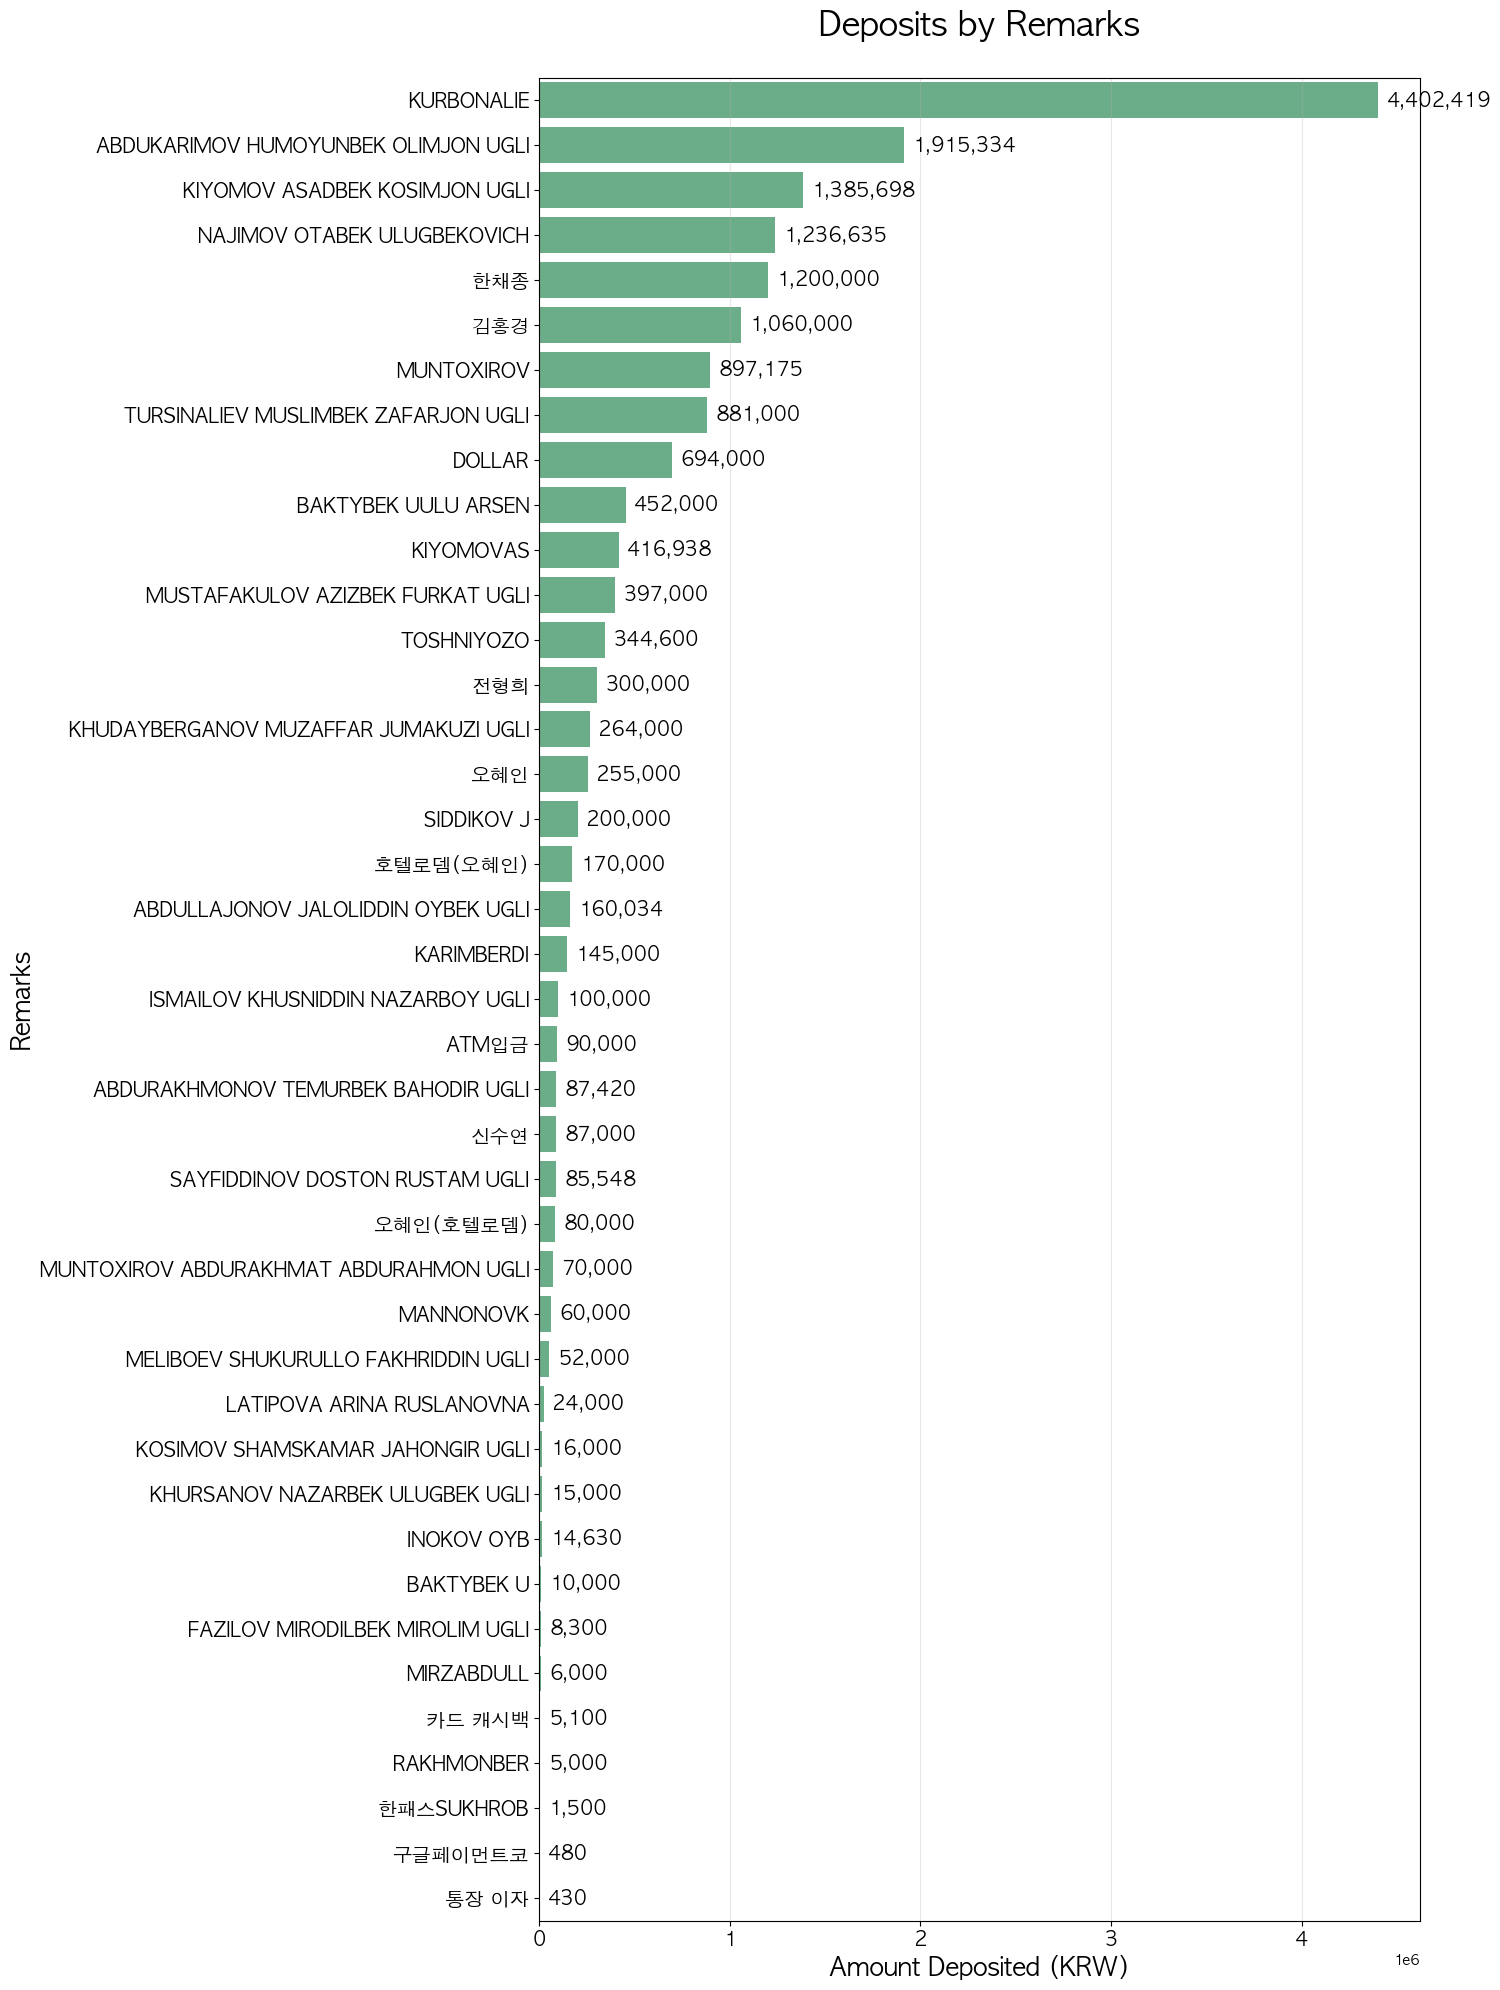

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Korean font setup for macOS
plt.rcParams['font.family'] = ['AppleGothic', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False


# Read and prepare the data (common part)
df = pd.read_csv('transactions.csv')
df['Transaction_Amount'] = pd.to_numeric(df['Transaction_Amount'])

# Chart 1: Negative amounts (expenses)
expenses_df = df[df['Transaction_Amount'] < 0].copy()
expenses_df['Amount_Spent'] = abs(expenses_df['Transaction_Amount'])
remarks_spending = expenses_df.groupby('Remarks')['Amount_Spent'].sum().sort_values()

plt.figure(figsize=(16, 20))
bars = plt.barh(range(len(remarks_spending)), remarks_spending.values, color='#DC143C', alpha=0.7)
plt.title('Withdrawal by Remarks', fontsize=24, fontweight='bold', pad=30)
plt.xlabel('Amount Spent (KRW)', fontsize=18)
plt.ylabel('Remarks', fontsize=18)
plt.yticks(range(len(remarks_spending)), remarks_spending.index, fontsize=14)
plt.xticks(fontsize=14)
for i, v in enumerate(remarks_spending.values):
    plt.text(v + max(remarks_spending.values)*0.01, i, f'{int(v):,}', 
             va='center', fontweight='bold', fontsize=14)
plt.gca().set_ylim(-0.5, len(remarks_spending) - 0.5)
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig('visuals/spending_by_remarks_negative.png', dpi=300, bbox_inches='tight')
plt.show()

# Chart 2: Positive amounts
deposits_df = df[df['Transaction_Amount'] >= 0].copy()
remarks_deposits = deposits_df.groupby('Remarks')['Transaction_Amount'].sum().sort_values()

plt.figure(figsize=(15, 20))
bars = plt.barh(range(len(remarks_deposits)), remarks_deposits.values, color='#2E8B57', alpha=0.7)
plt.title('Deposits by Remarks', fontsize=24, fontweight='bold', pad=30)
plt.xlabel('Amount Deposited (KRW)', fontsize=18)
plt.ylabel('Remarks', fontsize=18)
plt.yticks(range(len(remarks_deposits)), remarks_deposits.index, fontsize=14)
plt.xticks(fontsize=14)
for i, v in enumerate(remarks_deposits.values):
    plt.text(v + max(remarks_deposits.values)*0.01, i, f'{int(v):,}', 
             va='center', fontweight='bold', fontsize=14)
plt.gca().set_ylim(-0.5, len(remarks_deposits) - 0.5)
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig('visuals/spending_by_remarks_positive.png', dpi=300, bbox_inches='tight')
plt.show()

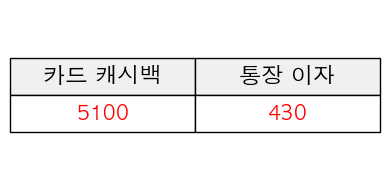

In [14]:
# individual_transactions('카드 캐시백')
# individual_transactions('카드 캐시백, 토스 캐시백, 통장 이자')

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('transactions.csv')

total_cashback = df[df['Remarks'] == '카드 캐시백']['Transaction_Amount'].sum()
total_interest = df[df['Remarks'] == '통장 이자']['Transaction_Amount'].sum()

# Create the data
data = {'카드 캐시백': [total_cashback], '통장 이자': [total_interest]}
tb = pd.DataFrame(data)

# Create a figure and axis
fig, ax = plt.subplots(figsize=(4,2))
ax.axis('off')  # remove axes

# Create table
table = ax.table(cellText=tb.values,
                 colLabels=tb.columns,
                 cellLoc='center',
                 colLoc='center',
                 loc='center')

# Style the table
table.auto_set_font_size(False)
table.set_fontsize(14)
table.scale(1, 2)  # scale height for better appearance

# Make headers bold and red
for (row, col), cell in table.get_celld().items():
    if row == 0:  # header row
        cell.set_text_props(weight='bold', color='black', fontsize=16)
        cell.set_facecolor('#f0f0f0')  # light gray background
    else:
        cell.set_text_props(weight='bold', color='red', fontsize=14)

plt.tight_layout()
plt.savefig('visuals/cashback_and_interest.png', dpi=300, bbox_inches='tight')
plt.show()



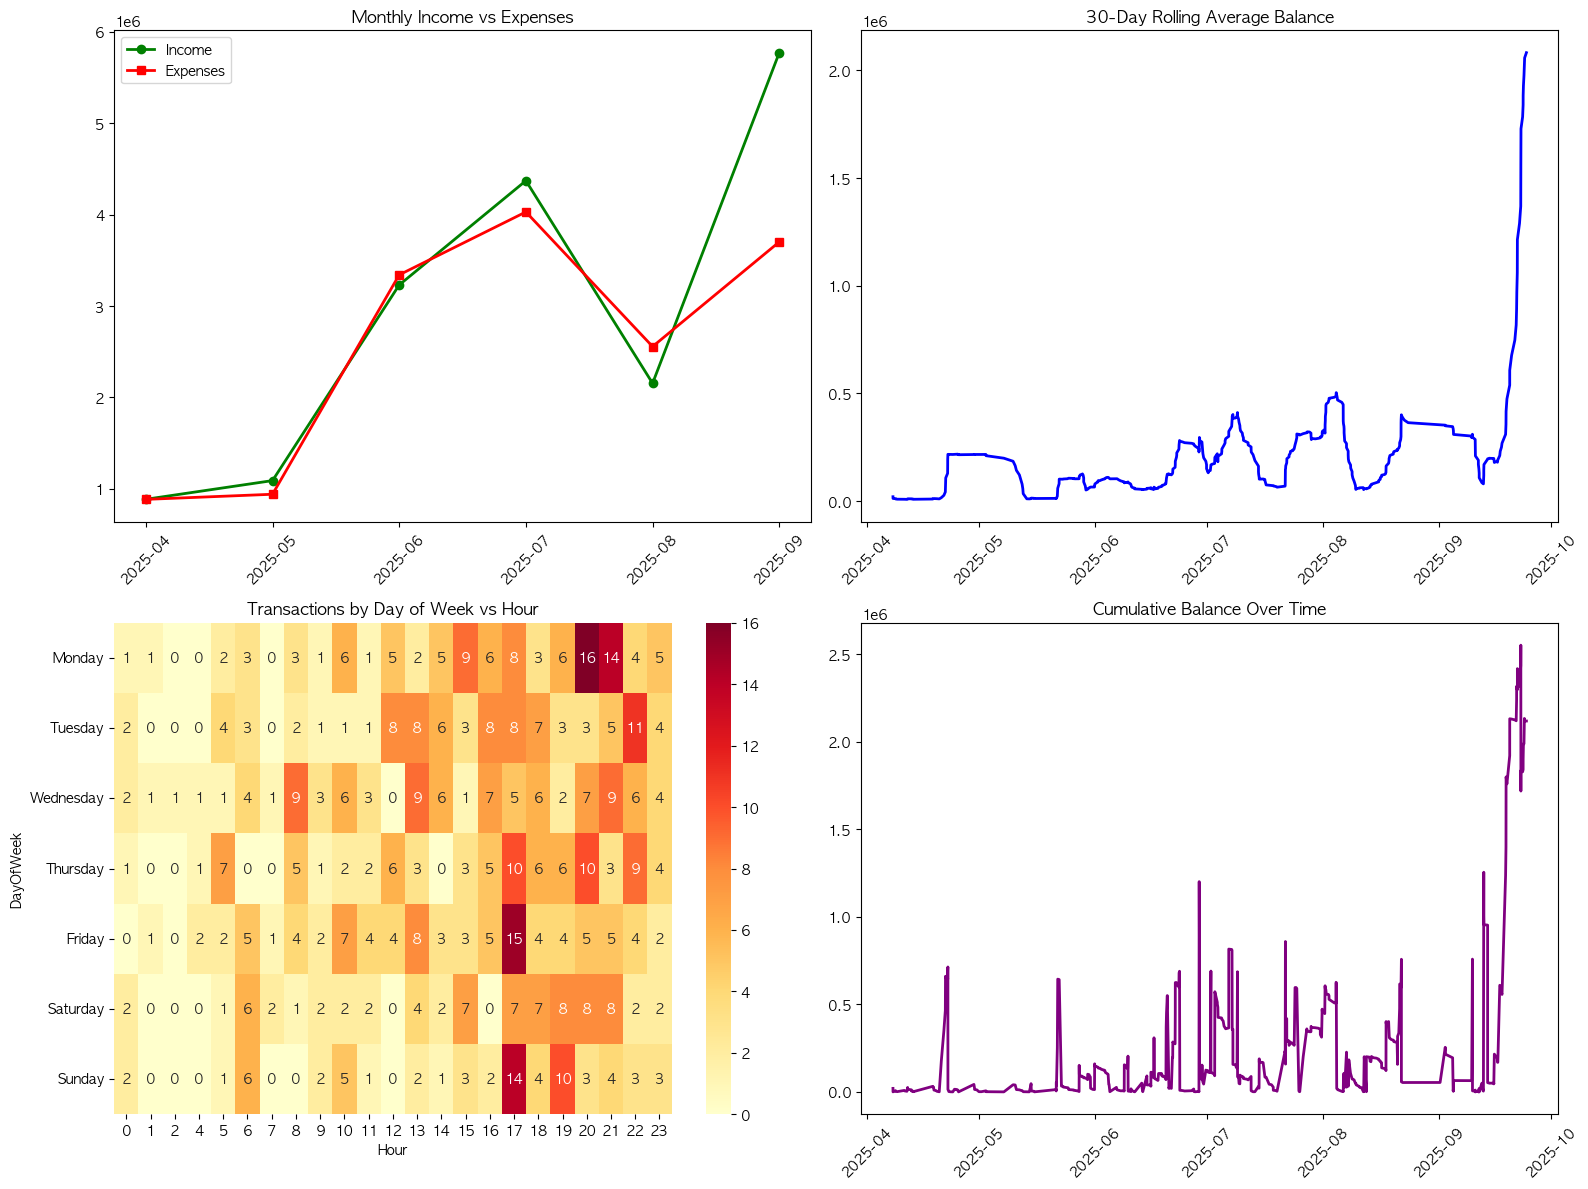

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

# Read and prepare data
df = pd.read_csv('transactions.csv')
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Transaction_Amount'] = pd.to_numeric(df['Transaction_Amount'])
df['Month'] = df['DateTime'].dt.to_period('M')
df['DayOfWeek'] = df['DateTime'].dt.day_name()
df['Hour'] = df['DateTime'].dt.hour

# Monthly income vs expenses
income_types = ['Deposit', 'Cashback', 'Interest Deposit']
expense_types = ['Withdrawal', 'Check Card', 'ATM Withdrawal']
monthly_income = df[df['Transaction_Type'].isin(income_types)].groupby('Month')['Transaction_Amount'].sum()
monthly_expenses = df[df['Transaction_Type'].isin(expense_types)].groupby('Month')['Transaction_Amount'].sum().abs()

# Rolling balance (30-day)
df_sorted = df.sort_values('DateTime')
df_sorted['Cumulative_Balance'] = df_sorted['Transaction_Amount'].cumsum()
df_sorted['Rolling_30d'] = df_sorted['Cumulative_Balance'].rolling(window=30, min_periods=1).mean()

# Heatmap data
heatmap_data = df.groupby(['DayOfWeek', 'Hour']).size().unstack(fill_value=0)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = heatmap_data.reindex(day_order)

# Create plots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
# fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

# 1. Monthly Income vs Expenses
months = [str(m) for m in monthly_income.index]
ax1.plot(months, monthly_income.values, marker='o', label='Income', color='green', linewidth=2)
ax1.plot(months, monthly_expenses.values, marker='s', label='Expenses', color='red', linewidth=2)
ax1.set_title('Monthly Income vs Expenses')
ax1.legend()
ax1.tick_params(axis='x', rotation=45)

# 2. Rolling 30-day Balance
ax2.plot(df_sorted['DateTime'], df_sorted['Rolling_30d'], color='blue', linewidth=2)
ax2.set_title('30-Day Rolling Average Balance')
ax2.tick_params(axis='x', rotation=45)

# 3. Transaction Heatmap
sb.heatmap(heatmap_data, annot=True, fmt='d', cmap='YlOrRd', ax=ax3)
ax3.set_title('Transactions by Day of Week vs Hour')

# 4. Cumulative Balance
ax4.plot(df_sorted['DateTime'], df_sorted['Cumulative_Balance'], color='purple', linewidth=2)
ax4.set_title('Cumulative Balance Over Time')
ax4.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('visuals/time_series_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()